# Week 5 — Support Vector Machines: Kernels and Regularisation
Weeks 2–4 used only **straight-line** (linear) models: each ratio pushes risk up or down
by a fixed amount. This week tests whether a model that can draw **curved** boundaries finds more.

**The question:** is bankruptcy risk a straight-line function of the ratios — or do curves and combinations matter?

**Research questions:**
- **RQ1:** is Week 4's U-shaped horizon pattern specific to linear models? (The proposal: "test whether decay is linear-model-specific".)
- **RQ3:** does the same hold in the Taiwanese data?

## Datasets used

- **Polish Companies Bankruptcy** — UCI, DOI [10.24432/C5F600](https://doi.org/10.24432/C5F600).
  - **Main file:** `polish_predict_3y.csv` — Steps 1–7. Same cleaning, 78 columns and train/test split as Weeks 2–3
    (the same 2,084 test firms).
  - **All five horizons:** `polish_predict_1y.csv` … `polish_predict_5y.csv` — Step 8 only (RQ1). Each modelled separately.
- **Taiwanese Bankruptcy Prediction** — UCI, DOI [10.24432/C5004D](https://doi.org/10.24432/C5004D).
  - **File used:** `taiwanese_bankruptcy.csv`, cleaned as in Week 4 (values above 1 → missing + flag) — Step 9 only (RQ3).
- **Not used:** the credit card data. Kernel SVMs slow down sharply with many rows (30,000), and RQ4 was answered in Week 4.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import average_precision_score

DATA = Path("../Dataset_new/CSV")
pd.set_option("display.width", 120)

## Step 1 — Load the data (same cleaning as Weeks 2–4)

In [2]:
COPIES = ["prof_gross_interest_assets", "prof_gross_profit_assets", "act_receivables_inv_days"]
DROP   = ["liq_quick_to_lt_liab", "grow_sales_growth"]

def load_polish(h, flags=True):
    # One horizon: remove duplicate rows, drop copied / high-blank columns, add blank-pattern flags
    df = pd.read_csv(DATA / f"polish_predict_{h}y.csv")
    all64 = [c for c in df.columns if c not in ("class", "years_ahead")]
    df = df.drop_duplicates(subset=all64).reset_index(drop=True)
    cols = [c for c in all64 if c not in COPIES + DROP]
    if flags:
        blank = df[all64].isna()
        blank = blank.loc[:, blank.any()]
        for c in blank.T.drop_duplicates().index:
            df["blank_" + c] = df[c].isna().astype(int)
            cols.append("blank_" + c)
    return df[cols], df["class"]

def load_taiwan():
    # Week 4 cleaning: values above the documented 0–1 range → missing + "out_" flag
    tw = pd.read_csv(DATA / "taiwanese_bankruptcy.csv")
    X = tw[[c for c in tw.columns if c not in ("Bankrupt?", "Net Income Flag")]].copy()
    for c in [c for c in X.columns if (X[c] > 1).any()]:
        X["out_" + c] = (X[c] > 1).astype(int)
        X.loc[X[c] > 1, c] = np.nan
    return X, tw["Bankrupt?"]

X, y = load_polish(3)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Polish 3y: {X.shape[1]} columns · train {len(X_train)} firms ({y_train.sum()} bankrupt) · "
      f"test {len(X_test)} firms ({y_test.sum()} bankrupt)")

Polish 3y: 78 columns · train 8332 firms (394 bankrupt) · test 2084 firms (99 bankrupt)


## Step 2 — How an SVM works

- **The idea:** draw the boundary between bankrupt and surviving firms that leaves the **widest gap** (the "margin")
  on both sides. Only the firms closest to the boundary — the **support vectors** — decide where it goes.
- **C — the regularisation hyperparameter.** It sets how much the SVM is allowed to bend to fit awkward firms:
  - small C: wide margin, tolerates mistakes → simple, may underfit;
  - large C: narrow margin, tries to classify every training firm correctly → complex, may overfit.
  It plays the same role as C in Weeks 2–4: large C = weak penalty.
- **The kernel trick:** a straight boundary can't separate groups that sit in curved patterns. A **kernel** lets the
  SVM draw curved boundaries **without** building new columns by hand (no AGE² or interaction terms as in Week 1).
  - **linear** — a straight boundary;
  - **polynomial** — curves and combinations of columns up to a chosen degree;
  - **RBF** — a firm is judged by how similar it is to nearby firms; can draw almost any shape.
- **gamma (RBF only)** sets how far "nearby" reaches:
  - small gamma:  each firm influences a wide area → smooth boundary;
  - large gamma:  each firm influences only its immediate neighbours → wiggly boundary that can memorise.

**Scaling is essential.** The RBF kernel measures distances between firms, so a column in millions would swamp the
rest. Same quantile transform as Weeks 2–4.

**Scoring:** the SVM gives each firm a **score** (distance from the boundary). PR-AUC only needs the ranking, so
the score is used directly.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORES = {"train_PR_AUC": 3, "val_PR_AUC": 3, "val_sd": 3, "gap": 3}   # round scores only, not C / gamma

def pipe(clf):
    return make_pipeline(SimpleImputer(strategy="median"),
                         QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0),
                         clf)

def run_cv(clf, X=X_train, y=y_train, cv=cv):
    r = cross_validate(pipe(clf), X, y, cv=cv, scoring="average_precision",
                       return_train_score=True, n_jobs=-1)
    return {"train_PR_AUC": r["train_score"].mean(), "val_PR_AUC": r["test_score"].mean(),
            "val_sd": r["test_score"].std(), "gap": r["train_score"].mean() - r["test_score"].mean()}

def one_se(table):
    # Simplest setting within one standard error of the best (here: the row with the smallest train–val gap)
    best = table.loc[table["val_PR_AUC"].idxmax()]
    ok = table[table["val_PR_AUC"] >= best["val_PR_AUC"] - best["val_sd"] / np.sqrt(5)]
    return ok.loc[ok["gap"].idxmin()]

logit = run_cv(LogisticRegression(max_iter=5000))
print(f"Reference — logistic regression (Week 4 setup): validation {logit['val_PR_AUC']:.3f}, gap {logit['gap']:.3f}")

Reference — logistic regression (Week 4 setup): validation 0.404, gap 0.074


## Step 3 — Linear SVM

A straight boundary, like logistic regression. **Tuned:** C from 0.001 to 1.

In [4]:
linear_table = pd.DataFrame([{"C": C, **run_cv(LinearSVC(C=C, max_iter=20000))}
                             for C in [0.001, 0.01, 0.1, 1]])
linear_table.round(3)

,C,train_PR_AUC,val_PR_AUC,val_sd,gap
0,0.001,0.368,0.334,0.039,0.034
1,0.010,0.446,0.394,0.054,0.052
2,0.100,0.497,0.423,0.068,0.074
3,1.000,0.521,0.432,0.062,0.089


**What we found:**
- **A linear SVM performs like logistic regression:** best C = 1, validation 0.432 vs logistic 0.404 — within the
  fold-to-fold noise (± 0.06). Both draw a straight boundary, so they find the same thing.
- **C behaves as expected:** small C (0.001) underfits (0.334); larger C fits better, with the gap growing slowly
  (0.034 → 0.089).

## Step 4 — RBF kernel: tuning C and gamma together

24 combinations: C from 0.1 to 10,000 and gamma from 0.0001 to 0.1. About 2 minutes.

In [5]:
C_GRID     = [0.1, 1, 10, 100, 1000, 10000]
GAMMA_GRID = [0.0001, 0.001, 0.01, 0.1]

rbf_table = pd.DataFrame([{"C": C, "gamma": g, **run_cv(SVC(kernel="rbf", C=C, gamma=g))}
                          for C in C_GRID for g in GAMMA_GRID])
best_rbf = rbf_table.loc[rbf_table["val_PR_AUC"].idxmax()]
choice_rbf = one_se(rbf_table)
print(f"Best:   C = {best_rbf['C']:g}, gamma = {best_rbf['gamma']:g} → validation {best_rbf['val_PR_AUC']:.3f}, gap {best_rbf['gap']:.3f}")
print(f"Chosen (within one SE of best, smallest gap): C = {choice_rbf['C']:g}, gamma = {choice_rbf['gamma']:g} "
      f"→ validation {choice_rbf['val_PR_AUC']:.3f}, gap {choice_rbf['gap']:.3f}")
rbf_table.round(SCORES)

Best:   C = 1000, gamma = 0.001 → validation 0.662, gap 0.292
Chosen (within one SE of best, smallest gap): C = 1000, gamma = 0.001 → validation 0.662, gap 0.292


,C,gamma,train_PR_AUC,val_PR_AUC,val_sd,gap
0,0.1,0.0001,0.492,0.443,0.078,0.049
1,0.1,0.0010,0.576,0.472,0.083,0.104
2,0.1,0.0100,0.725,0.456,0.062,0.269
3,0.1,0.1000,0.998,0.356,0.038,0.642
4,1.0,0.0001,0.565,0.481,0.088,0.084
5,1.0,0.0010,0.578,0.474,0.084,0.104
6,1.0,0.0100,0.857,0.517,0.048,0.340
7,1.0,0.1000,1.000,0.351,0.037,0.648
8,10.0,0.0001,0.572,0.486,0.093,0.086
9,10.0,0.0010,0.673,0.558,0.056,0.115


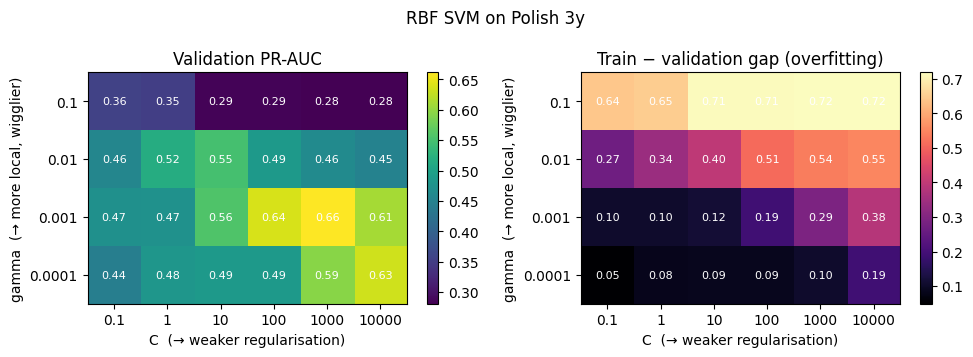

In [6]:
# Figure candidate: validation PR-AUC and overfitting gap across C and gamma
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, title, cmap in [(axes[0], "val_PR_AUC", "Validation PR-AUC", "viridis"),
                             (axes[1], "gap", "Train − validation gap (overfitting)", "magma")]:
    grid = rbf_table.pivot(index="gamma", columns="C", values=col)
    im = ax.imshow(grid.values, cmap=cmap, aspect="auto", origin="lower")
    ax.set_xticks(range(len(grid.columns)), [f"{c:g}" for c in grid.columns])
    ax.set_yticks(range(len(grid.index)), [f"{g:g}" for g in grid.index])
    ax.set_xlabel("C  (→ weaker regularisation)")
    ax.set_ylabel("gamma  (→ more local, wigglier)")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(j, i, f"{grid.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white")
    ax.set_title(title)
    fig.colorbar(im, ax=ax)
fig.suptitle("RBF SVM on Polish 3y")
plt.tight_layout()
plt.show()

**How to read the two maps:** left = how well each setting predicts unseen firms; right = how much it memorises.
The best settings are bright on the left **and** dark on the right.

**What we found:**
- **The curved boundary is much better:** best setting C = 1000, gamma = 0.001 → validation **0.662**, against 0.404
  for logistic regression — about 1.6 times higher.
- **Large gamma memorises:** at gamma = 0.1 every C gives train ≈ 1.00 but validation only 0.28–0.36. Each firm only
  influences its immediate neighbours, so the model learns the training firms one by one.
- **Small gamma needs a large C:** with gamma = 0.001 the score climbs from 0.472 (C = 0.1) to 0.662 (C = 1000) —
  a smooth boundary has to be allowed to bend before it helps.
- **The chosen model still overfits** (train 0.954, gap 0.29), but no simpler setting comes within one standard error
  of it — the extra fit is not all memorising; part of it is real curved structure.

## Step 5 — Polynomial kernel

Curves and combinations of columns up to degree 2 or 3 — the automatic version of Week 1's squared and interaction
terms. Tuned over C.

In [7]:
poly_table = pd.DataFrame([{"degree": d, "C": C, **run_cv(SVC(kernel="poly", degree=d, C=C))}
                           for d in [2, 3] for C in [0.01, 0.1, 1, 10, 100]])
best_poly = poly_table.loc[poly_table["val_PR_AUC"].idxmax()]
print(f"Best: degree {best_poly['degree']:g}, C = {best_poly['C']:g} → validation {best_poly['val_PR_AUC']:.3f}")
poly_table.round(3)

Best: degree 3, C = 100 → validation 0.644


,degree,C,train_PR_AUC,val_PR_AUC,val_sd,gap
0,2,0.01,0.547,0.461,0.082,0.086
1,2,0.10,0.561,0.471,0.086,0.091
2,2,1.00,0.563,0.473,0.081,0.090
3,2,10.00,0.727,0.605,0.064,0.122
4,2,100.00,0.858,0.644,0.064,0.214
5,3,0.01,0.576,0.462,0.088,0.114
6,3,0.10,0.585,0.466,0.086,0.119
7,3,1.00,0.656,0.525,0.062,0.131
8,3,10.00,0.819,0.621,0.060,0.197
9,3,100.00,0.941,0.644,0.055,0.297


**What we found:**
- **Curves and combinations help here too:** degree 3, C = 100 → validation 0.644; degree 2 reaches the same 0.644.
- Like RBF, it needs a large C (weak regularisation): at C ≤ 1 both degrees stay at 0.46–0.53.
- The score levels off between C = 10 and C = 100 (0.605–0.644), so the grid is wide enough.
- This is the automatic version of Week 1's squared and interaction terms — and it gains far more here than AGE² did there.

## Step 6 — Final comparison on the test set

Each model refitted on all training firms with its chosen settings, then scored **once** on the same test firms as
Weeks 2–3. The 95% range comes from re-drawing the test set 1,000 times.

In [8]:
C_LIN = linear_table.loc[linear_table["val_PR_AUC"].idxmax(), "C"]
final = {
    "logistic regression (Week 4)":                   LogisticRegression(max_iter=5000),
    f"linear SVM (C={C_LIN:g})":                      LinearSVC(C=C_LIN, max_iter=20000),
    f"polynomial SVM (degree {best_poly['degree']:g}, C={best_poly['C']:g})":
        SVC(kernel="poly", degree=int(best_poly["degree"]), C=best_poly["C"]),
    f"RBF SVM (C={choice_rbf['C']:g}, gamma={choice_rbf['gamma']:g})":
        SVC(kernel="rbf", C=choice_rbf["C"], gamma=choice_rbf["gamma"]),
}

def score(model, X):
    return model.decision_function(X) if hasattr(model, "decision_function") else model.predict_proba(X)[:, 1]

rng = np.random.default_rng(0)
yt = y_test.to_numpy()
boot = [rng.integers(0, len(yt), len(yt)) for _ in range(1000)]

rows = []
for name, clf in final.items():
    m = pipe(clf).fit(X_train, y_train)
    p_tr, p_te = score(m, X_train), score(m, X_test)
    tr, te = average_precision_score(y_train, p_tr), average_precision_score(yt, p_te)
    lo, hi = np.percentile([average_precision_score(yt[i], p_te[i]) for i in boot], [2.5, 97.5])
    rows.append({"model": name, "train_PR_AUC": tr, "test_PR_AUC": te, "test_95%_range": f"{lo:.3f}–{hi:.3f}",
                 "gap": tr - te, "test_lift": te / yt.mean()})
comparison = pd.DataFrame(rows)
comparison.round(3)

,model,train_PR_AUC,test_PR_AUC,test_95%_range,gap,test_lift
0,logistic regression (Week 4),0.469,0.485,0.386–0.596,-0.016,10.206
1,linear SVM (C=1),0.514,0.469,0.374–0.585,0.045,9.876
2,"polynomial SVM (degree 3, C=100)",0.942,0.699,0.602–0.786,0.242,14.723
3,"RBF SVM (C=1000, gamma=0.001)",0.953,0.715,0.622–0.802,0.237,15.054


**What we found:**
- **RBF SVM: test 0.715 (95% range 0.62–0.80), lift 15.1×.** Polynomial SVM: 0.699 (0.60–0.79).
- **Linear models: about 0.47–0.49** (logistic 0.485, linear SVM 0.469).
- **This gain is real, not noise:** RBF's lowest plausible score (0.62) is above logistic regression's highest (0.60).
- **Best result so far** — Week 3's best was 0.540 (forward selection, 16 columns).
- **Overfitting:** the curved models have large train–test gaps (0.24), yet still score highest on unseen firms.
  A big gap is a warning sign, not proof of a bad model; the test score decides.

For reference, Week 3's best test score was forward selection with 16 columns: 0.540.

## Step 7 — Why does the curved model win? A simple check

If curves matter, **one** ratio on its own should show it: risk that rises, then flattens, or only kicks in past a
threshold. For the three columns all methods agreed on in Week 3, compare a straight-line fit with the actual
bankruptcy rate in each tenth of the firms (deciles).

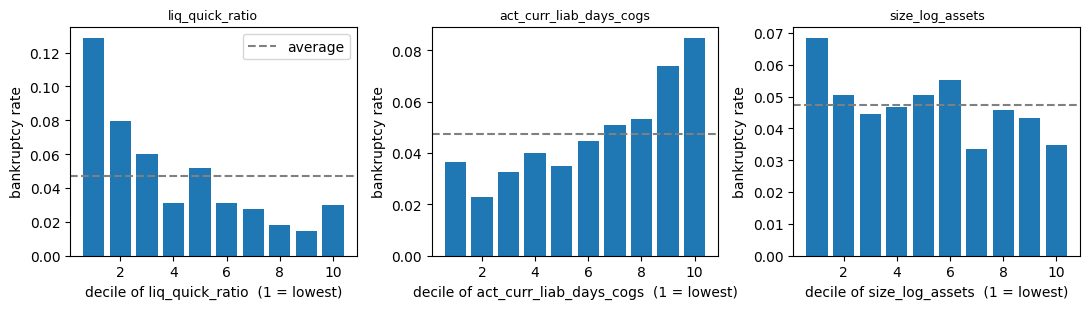

In [9]:
# Bankruptcy rate in each decile of the ratio (training firms only)
check = ["liq_quick_ratio", "act_curr_liab_days_cogs", "size_log_assets"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col in zip(axes, check):
    d = pd.DataFrame({"x": X_train[col], "y": y_train}).dropna()
    d["decile"] = pd.qcut(d["x"].rank(method="first"), 10, labels=False) + 1
    rate = d.groupby("decile")["y"].mean()
    ax.bar(rate.index, rate.values)
    ax.axhline(y_train.mean(), color="grey", linestyle="--", label="average")
    ax.set_xlabel(f"decile of {col}  (1 = lowest)")
    ax.set_ylabel("bankruptcy rate")
    ax.set_title(col, fontsize=9)
axes[0].legend()
plt.tight_layout()
plt.show()

**How to read:** a straight-line model assumes risk changes by the same amount from one decile to the next.
If the bars instead jump, flatten or form a U, a curved model can capture what a straight line misses.

**What we found** (bankruptcy rate by decile; average 4.7%):
- **Quick ratio — risk is concentrated at the bottom:** 12.8% in the lowest decile, then 7.9%, 6.0%, and flat at
  about 1.4–5% from the 4th decile up. Being short of cash matters a lot; having *more* than enough barely matters.
  A straight line can't capture this sharp drop followed by a flat stretch.
- **Days to pay short-term debt — risk kicks in late:** flat at 2.3–4.5% for the lowest six deciles, then rising to
  7.4% and 8.5% in the top two. A threshold, not a steady slope.
- **Size — weak and uneven:** highest in the smallest firms (6.8%), then flat around 3.4–5.5%.
- **So bankruptcy risk works through thresholds:** ratios matter mostly at their extremes. That is exactly what
  curved models can capture and straight-line models cannot.

## Step 8 — RQ1: does a curved model change the horizon pattern?

Week 4 (logistic regression) found a U-shape: 1 year 0.69 → 3 years 0.39 → 5 years 0.64 (normalised PR-AUC).
Here: logistic regression and the chosen RBF SVM on all five horizons, 5 folds × 3 repeats each.

- Same RBF settings at every horizon (chosen on the 3-year file), so only the data changes.
- **Normalised PR-AUC** = (PR-AUC − base rate) ÷ (1 − base rate): 0 = guessing, 1 = perfect — fair across
  horizons with different base rates.

In [10]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
models = {"logistic": LogisticRegression(max_iter=5000),
          "RBF SVM": SVC(kernel="rbf", C=choice_rbf["C"], gamma=choice_rbf["gamma"])}

rows = []
for h in range(1, 6):
    Xh, yh = load_polish(h)
    base = yh.mean()
    row = {"years_ahead": h, "base_rate": base}
    for name, clf in models.items():
        r = cross_validate(pipe(clf), Xh, yh, cv=rcv, scoring="average_precision",
                           return_train_score=True, n_jobs=-1)
        norm = (r["test_score"] - base) / (1 - base)
        row[f"{name}_normalised"] = norm.mean()
        row[f"{name}_sd"] = norm.std()
        row[f"{name}_gap"] = r["train_score"].mean() - r["test_score"].mean()
    rows.append(row)
horizons = pd.DataFrame(rows)
horizons.round(3)

,years_ahead,base_rate,logistic_normalised,logistic_sd,logistic_gap,RBF SVM_normalised,RBF SVM_sd,RBF SVM_gap
0,1,0.070,0.690,0.020,0.054,0.759,0.026,0.203
1,2,0.053,0.513,0.040,0.066,0.735,0.018,0.210
2,3,0.047,0.387,0.051,0.066,0.668,0.047,0.270
3,4,0.039,0.395,0.058,0.083,0.670,0.049,0.269
4,5,0.039,0.639,0.060,0.067,0.711,0.047,0.236


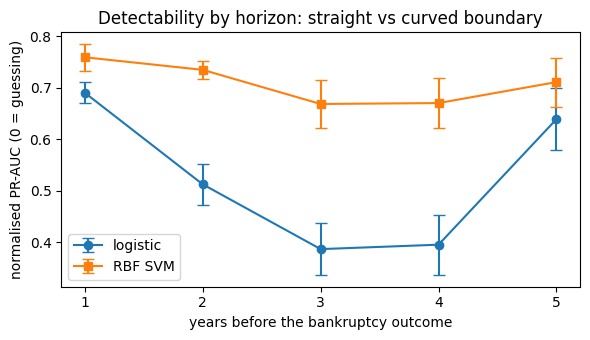

In [11]:
# Figure candidate: horizon pattern, linear vs curved model
fig, ax = plt.subplots(figsize=(6, 3.5))
for name, marker in [("logistic", "o"), ("RBF SVM", "s")]:
    ax.errorbar(horizons["years_ahead"], horizons[f"{name}_normalised"], yerr=horizons[f"{name}_sd"],
                fmt=f"{marker}-", capsize=4, label=name)
ax.set_xticks(range(1, 6))
ax.set_xlabel("years before the bankruptcy outcome")
ax.set_ylabel("normalised PR-AUC (0 = guessing)")
ax.set_title("Detectability by horizon: straight vs curved boundary")
ax.legend()
plt.tight_layout()
plt.show()

**What we found** (normalised PR-AUC, 0 = guessing, 1 = perfect):
- **Logistic (Week 4):** 1y 0.69 → 2y 0.51 → 3y 0.39 → 4y 0.40 → 5y 0.64 — the U-shape.
- **RBF SVM:** 1y **0.76** → 2y **0.74** → 3y **0.67** → 4y **0.67** → 5y **0.71** — **much flatter**.
- **The U-shape is mostly a linear-model effect.** The curved model gains most at 3–4 years (+0.28) and least at
  1 year (+0.07). Mid-range horizons hold signal a straight line cannot use.
- **There is still a mild decline:** 1 year remains the most detectable, and 3–4 years the least.
- **Overfitting:** RBF gaps are 0.20–0.27 at every horizon (logistic 0.05–0.08), yet its validation scores are
  higher everywhere.

## Step 9 — RQ3: the Taiwanese data

Same comparison on the cleaned Taiwanese data (Week 4). Taiwan has only 220 bankrupt firms for 118 columns, so a
flexible model has more room to memorise. A small C × gamma grid is tuned here, because the best settings
need not transfer from Poland.

In [12]:
X_tw, y_tw = load_taiwan()
Xt_train, Xt_test, yt_train, yt_test = train_test_split(X_tw, y_tw, test_size=0.2, stratify=y_tw, random_state=42)

tw_rows = [{"model": "logistic", "C": 1, "gamma": None,
            **run_cv(LogisticRegression(max_iter=5000), Xt_train, yt_train)}]
for C in [0.1, 1, 10, 100]:
    for g in [0.0001, 0.001, 0.01]:
        tw_rows.append({"model": "RBF SVM", "C": C, "gamma": g,
                        **run_cv(SVC(kernel="rbf", C=C, gamma=g), Xt_train, yt_train)})
tw_table = pd.DataFrame(tw_rows)
tw_table.round(SCORES)

,model,C,gamma,train_PR_AUC,val_PR_AUC,val_sd,gap
0,logistic,1.0,NaN,0.622,0.407,0.026,0.215
1,RBF SVM,0.1,0.0001,0.607,0.363,0.023,0.244
2,RBF SVM,0.1,0.0010,0.768,0.400,0.028,0.368
3,RBF SVM,0.1,0.0100,0.992,0.374,0.057,0.618
4,RBF SVM,1.0,0.0001,0.644,0.394,0.034,0.249
5,RBF SVM,1.0,0.0010,0.768,0.400,0.028,0.369
6,RBF SVM,1.0,0.0100,0.993,0.374,0.057,0.619
7,RBF SVM,10.0,0.0001,0.645,0.399,0.038,0.246
8,RBF SVM,10.0,0.0010,0.848,0.413,0.035,0.435
9,RBF SVM,10.0,0.0100,1.000,0.363,0.060,0.637


**What we found:**
- **No gain in Taiwan:** best RBF (C = 10, gamma = 0.001) validation 0.413 vs logistic regression 0.407 — the same.
- **And much more memorising:** that RBF setting has a gap of 0.44 (train 0.848); logistic 0.22.
- **Why:** only 176 bankrupt firms in the training data for 118 columns. A flexible model has too few examples to
  learn real curves, so it memorises instead. Polish 3y has more than twice as many (394).
- **RQ3:** the curved-boundary gain does **not** transfer to Taiwan — or there is not enough data there to find it.

## Expected vs unexpected

These expectations were written **before** Week 5 ran: in the capstone proposal and the findings log (Week 4).

**Expected**
- SVM tests "whether decay is linear-model-specific" (proposal); "does a non-linear model change the shape?"
  (findings log) → yes: the RBF SVM flattens the U from 0.69 / 0.39 / 0.64 to 0.76 / 0.67 / 0.71 →
  **confirmed — the U-shape is largely a linear-model effect**.
- A flexible model will overfit where bankrupt firms are scarce (Week 2: penalty matters most for Taiwan) → Taiwan
  RBF gap 0.44 with no gain over logistic → **confirmed**.
- Large gamma memorises → train ≈ 1.00, validation 0.28–0.36 at gamma = 0.1 → **confirmed**.

**Unexpected**
- **How big the gain is:** test PR-AUC 0.485 → 0.715, the largest jump in any week — bigger than penalties (Week 2),
  selection (Week 3) or scaling choices (Week 4).
- **The best setting is a weakly regularised one** (C = 1000) with a large train–test gap that still predicts best.
- **Threshold effects are visible in single ratios:** the quick ratio's risk sits almost entirely in its lowest decile.

## Conclusions

1. **Linear SVM vs logistic regression:** the same performance (validation 0.43 vs 0.40; test 0.47 vs 0.49) — a
   straight boundary finds the same signal either way.
2. **RBF kernel:** validation 0.662 at C = 1000, gamma = 0.001 — 1.6 times logistic regression. Large gamma memorises;
   small gamma needs a large C.
3. **Polynomial kernel:** nearly as good (0.644 validation, 0.699 test) — curves and combinations of ratios matter.
4. **Test set:** RBF SVM 0.715 (0.62–0.80), lift 15.1× — clearly above the linear models (about 0.47–0.49) and the best
   result so far.
5. **Why curves help:** bankruptcy risk works through thresholds — e.g. 12.8% in the lowest quick-ratio decile, flat
   1.4–5% above the 4th. Ratios matter mostly at their extremes.
6. **RQ1 — horizon:** with a curved model, detectability is much flatter (0.76 at 1 year, 0.67 at 3–4 years, 0.71 at
   5 years). Week 4's U-shape was largely a limitation of straight-line models; a mild decline remains.
7. **RQ3 — Taiwan:** no gain (0.413 vs 0.407) and heavy memorising (gap 0.44) — too few bankrupt firms (176) for a
   flexible model.
8. **Overfitting and hyperparameters:** C = regularisation (small = wide margin, simple); gamma = how local each firm's
   influence is (large = wiggly, memorises). The best Polish model is weakly regularised (C = 1000) with a smooth
   kernel (gamma = 0.001). The train–test gap is large (0.24) but the test score is the highest, so the gap reflects
   partial memorising on top of real structure.